In [20]:
# Install essential libraries and NLTK resources
!pip install pandas numpy matplotlib seaborn nltk scikit-learn tensorflow 
!python -m nltk.downloader punkt stopwords wordnet


C:\Users\NASIR ABBAS\AppData\Local\Programs\Python\Python39\lib\runpy.py:127: RuntimeWarning: 'nltk.downloader' found in sys.modules after import of package 'nltk', but prior to execution of 'nltk.downloader'; this may result in unpredictable behaviour
  warn(RuntimeWarning(msg))
[nltk_data] Downloading package punkt to C:\Users\NASIR
[nltk_data]     ABBAS\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to C:\Users\NASIR
[nltk_data]     ABBAS\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to C:\Users\NASIR
[nltk_data]     ABBAS\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [75]:
import pandas as pd
import numpy as np
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
import pickle
import joblib
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout



In [76]:
# Download necessary NLTK resources
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('punkt')  # Needed for word_tokenize

[nltk_data] Downloading package stopwords to C:\Users\NASIR
[nltk_data]     ABBAS\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to C:\Users\NASIR
[nltk_data]     ABBAS\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt to C:\Users\NASIR
[nltk_data]     ABBAS\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

In [77]:
# Load the dataset from the CSV file
df = pd.read_csv('Dataset.csv')
df.head()


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [78]:
df.shape

(5000, 2)

In [79]:
df['sentiment'].value_counts()

sentiment
negative    2532
positive    2468
Name: count, dtype: int64

In [82]:
df.isnull().sum()

review       0
sentiment    0
dtype: int64

In [83]:
df = df.dropna()

In [84]:
df.duplicated().sum()

3

In [85]:
df = df.drop_duplicates()

In [86]:
df.shape

(4997, 2)

In [87]:
# Initialize stopwords set and lemmatizer
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()


In [88]:
# Function to preprocess review text
def preprocess_text(text):
    # Remove HTML tags
    text = re.sub(r'<[^>]+>', '', text)
    
    # Remove special characters and numbers
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    
    # Convert to lowercase
    text = text.lower()
    
    # Tokenize
    words = nltk.word_tokenize(text)
    
    # Remove stopwords and lemmatize
    words = [lemmatizer.lemmatize(word) for word in words if word not in stop_words]
    
    return ' '.join(words)


In [89]:
# Apply the preprocessing function to the review column
df['cleaned_review'] = df['review'].apply(preprocess_text)


In [90]:
df['cleaned_review']

0       one reviewer mentioned watching oz episode you...
1       wonderful little production filming technique ...
2       thought wonderful way spend time hot summer we...
3       basically there family little boy jake think t...
4       petter matteis love time money visually stunni...
                              ...                        
4995    interesting slasher film multiple suspectsincl...
4996    watched series first came si year old watched ...
4997    jet li brings charismatic presence movie scree...
4998    rented movie hearing chris gore saying somethi...
4999    big disappointment think worst mastroiannimovi...
Name: cleaned_review, Length: 4997, dtype: object

In [91]:
# Convert sentiment labels to numeric values: 0 = negative, 1 = positive
df['sentiment_num'] = df['sentiment'].map({'negative': 0, 'positive': 1})


In [92]:
# Initialize TF-IDF Vectorizer with unigrams, bigrams, and trigrams
tfidf = TfidfVectorizer(ngram_range=(1, 3), max_features=5000)

# Fit and transform the cleaned reviews
X = tfidf.fit_transform(df['cleaned_review'])

# Target labels
y = df['sentiment_num']


In [93]:
# Split the data into training and testing sets (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)



In [94]:
# Display the shape of training and testing data
X_train.shape
X_test.shape


(1500, 5000)

In [95]:
# Initialize the Logistic Regression model
lr_model = LogisticRegression(max_iter=1000, random_state=42)

# Train the model on the training data
lr_model.fit(X_train, y_train)


LogisticRegression(max_iter=1000, random_state=42)

In [96]:
# Predict sentiment labels on the test data
y_pred = lr_model.predict(X_test)


In [97]:
# Print classification report and accuracy
print("Logistic Regression Performance:")
print(classification_report(y_test, y_pred))
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")


Logistic Regression Performance:
              precision    recall  f1-score   support

           0       0.87      0.86      0.87       760
           1       0.86      0.87      0.86       740

    accuracy                           0.87      1500
   macro avg       0.87      0.87      0.87      1500
weighted avg       0.87      0.87      0.87      1500

Accuracy: 0.8653


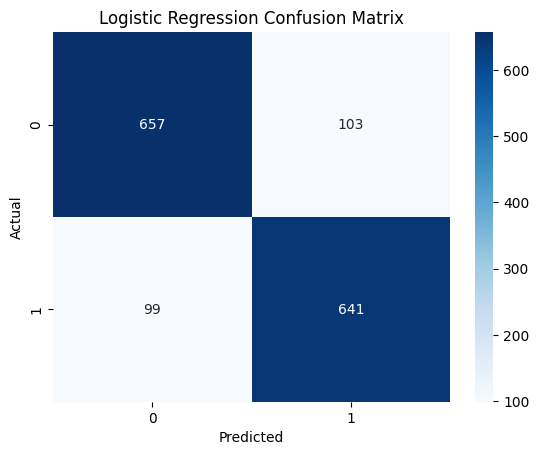

In [98]:
# Generate and plot confusion matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Logistic Regression Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()


In [99]:
# Initialize tokenizer with vocabulary size and out-of-vocabulary token
tokenizer = Tokenizer(num_words=10000, oov_token='<OOV>')

# Fit tokenizer on cleaned reviews
tokenizer.fit_on_texts(df['cleaned_review'])


In [100]:
# Convert cleaned reviews into sequences of integers
sequences = tokenizer.texts_to_sequences(df['cleaned_review'])


In [101]:
# Define maximum sequence length (can be average or fixed)
max_len = 200

# Pad sequences to ensure uniform length
X_seq = pad_sequences(sequences, maxlen=max_len, padding='post', truncating='post')


In [102]:
# Split sequences and labels into training and test sets
X_train_lstm, X_test_lstm, y_train_lstm, y_test_lstm = train_test_split(
    X_seq, y, test_size=0.3, random_state=42, stratify=y
)



In [103]:

# Display shapes of the training and test sets
X_train_lstm.shape
X_test_lstm.shape

(1500, 200)

In [104]:
# Vocabulary size +1 for padding token
vocab_size = len(tokenizer.word_index) + 1

# Embedding vector dimension
embedding_dim = 128

# Maximum input sequence length (must match padded sequence length)
max_len = 200


In [106]:
model = Sequential([
    Embedding(vocab_size, embedding_dim),  # Removed input_length to avoid warning
    LSTM(128, return_sequences=True),
    Dropout(0.5),
    LSTM(64),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])


In [107]:
# Force model building to initialize weights and check input shape
sample_input_shape = (1, max_len)  # batch size = 1, sequence length = max_len
model.build(sample_input_shape)

# Compile the model with binary cross-entropy loss and Adam optimizer
model.compile(
    loss='binary_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

# Display model architecture summary
print("LSTM Model Summary:")
model.summary()


LSTM Model Summary:


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)              │ (1, 200, 128)               │       6,296,960 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_8 (LSTM)                        │ (1, 200, 128)               │         131,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_8 (Dropout)                  │ (1, 200, 128)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_9 (LSTM)                        │ (1, 64)                     │          49,408 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_9 (Dropout)                  │ (1, 64)                     │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (1, 1)                      │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 6,478,017 (24.71 MB)

 Trainable params: 6,478,017 (24.71 MB)

 Non-trainable params: 0 (0.00 B)

In [108]:
# Early stopping to stop training if validation loss doesn't improve for 3 epochs
early_stop = EarlyStopping(monitor='val_loss', patience=3)


In [109]:
# Train the model with validation and early stopping
history = model.fit(
    X_train_lstm, y_train_lstm,
    validation_data=(X_test_lstm, y_test_lstm),
    epochs=5,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/5
55/55 ━━━━━━━━━━━━━━━━━━━━ 39s 567ms/step - accuracy: 0.5025 - loss: 0.6947 - val_accuracy: 0.4980 - val_loss: 0.6939
Epoch 2/5
55/55 ━━━━━━━━━━━━━━━━━━━━ 39s 538ms/step - accuracy: 0.5260 - loss: 0.6927 - val_accuracy: 0.4973 - val_loss: 0.6930
Epoch 3/5
55/55 ━━━━━━━━━━━━━━━━━━━━ 30s 540ms/step - accuracy: 0.5363 - loss: 0.6889 - val_accuracy: 0.5120 - val_loss: 0.6937
Epoch 4/5
55/55 ━━━━━━━━━━━━━━━━━━━━ 31s 558ms/step - accuracy: 0.5542 - loss: 0.6705 - val_accuracy: 0.4993 - val_loss: 0.7039
Epoch 5/5
55/55 ━━━━━━━━━━━━━━━━━━━━ 36s 653ms/step - accuracy: 0.5764 - loss: 0.6179 - val_accuracy: 0.4887 - val_loss: 0.7894


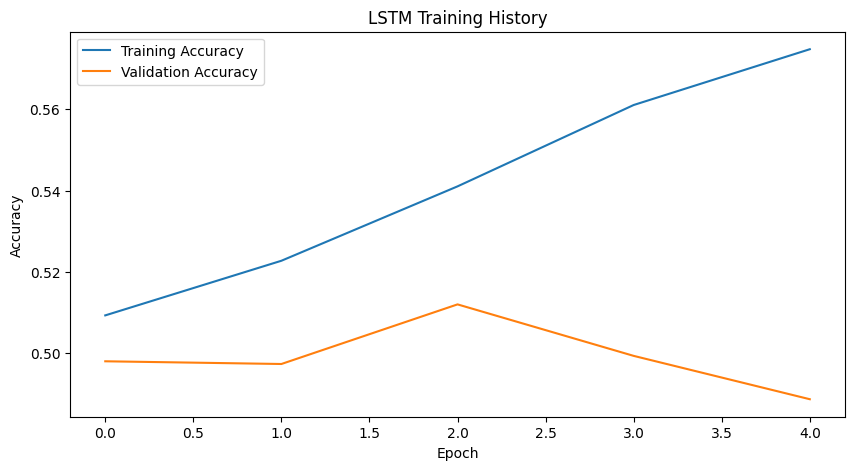

In [110]:
# Plot training history

plt.figure(figsize=(10, 5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('LSTM Training History')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [111]:
# Evaluate model
y_pred_lstm = (model.predict(X_test_lstm) > 0.5).astype(int)
print("\nLSTM Performance:")
print(classification_report(y_test_lstm, y_pred_lstm))
print(f"Accuracy: {accuracy_score(y_test_lstm, y_pred_lstm):.4f}")



47/47 ━━━━━━━━━━━━━━━━━━━━ 5s 107ms/step

LSTM Performance:
              precision    recall  f1-score   support

           0       0.47      0.08      0.14       760
           1       0.49      0.91      0.64       740

    accuracy                           0.49      1500
   macro avg       0.48      0.49      0.39      1500
weighted avg       0.48      0.49      0.38      1500

Accuracy: 0.4887


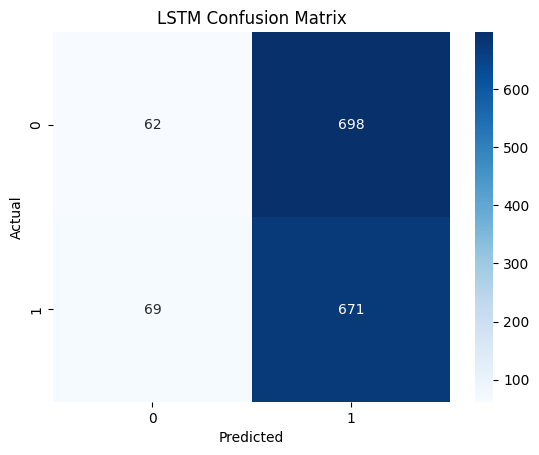

In [112]:
# Confusion matrix
cm_lstm = confusion_matrix(y_test_lstm, y_pred_lstm)
sns.heatmap(cm_lstm, annot=True, fmt='d', cmap='Blues')
plt.title('LSTM Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

Logistic Regression Accuracy: 0.8653
LSTM Accuracy: 0.4887


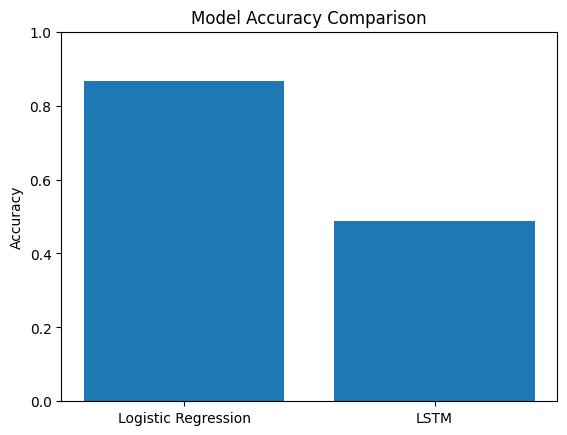

In [113]:
# Compare model performances
lr_acc = accuracy_score(y_test, y_pred)
lstm_acc = accuracy_score(y_test_lstm, y_pred_lstm)

print(f"Logistic Regression Accuracy: {lr_acc:.4f}")
print(f"LSTM Accuracy: {lstm_acc:.4f}")

# Plot comparison
plt.bar(['Logistic Regression', 'LSTM'], [lr_acc, lstm_acc])
plt.title('Model Accuracy Comparison')
plt.ylabel('Accuracy')
plt.ylim(0, 1)
plt.show()

In [116]:
# Save Logistic Regression model and vectorizer
joblib.dump(lr_model, 'logistic_regression_model.pkl')
joblib.dump(tfidf, 'tfidf_vectorizer.pkl')

# Save LSTM model and tokenizer
model.save('lstm_model.h5')
with open('tokenizer.pkl', 'wb') as handle:
    pickle.dump(tokenizer, handle, protocol=pickle.HIGHEST_PROTOCOL)